# International Debt Analysis System
**Python · SQL · Visualization** - World Bank International Debt Statistics

This notebook walks through the full data lifecycle required by the project spec:
1. Data collection (CSV → DataFrame)
2. Data preprocessing
3. Exploratory data analysis
4. Database design & SQL integration (30 queries)
5. Data visualization
6. Insights & reporting

The logic lives in `src/` so the notebook, `run_pipeline.py` and the Streamlit app all share it.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
from src import config, preprocessing, database, sql_runner, eda, plotting
pd.set_option('display.max_colwidth', 70); pd.set_option('display.float_format', '{:,.4f}'.format)

## 1. Data collection
Load the raw CSV into a pandas DataFrame and inspect structure, columns and data types.

In [2]:
raw = preprocessing.load_raw()
print(raw.shape)
raw.head()

(27445, 5)


,country_name,country_code,indicator_name,indicator_code,debt_usd
0,Afghanistan,AFG,Debt forgiveness grants (current US$),DT.DOD.MDRI.CD,"4,389,140.0000"
1,Afghanistan,AFG,"Debt service on external debt, general government sector (PPG) (TD...",DT.TDS.DEGG.CD,"12,017,000.0000"
2,Afghanistan,AFG,"Debt service on external debt, long-term (TDS, current US$)",DT.TDS.DLXF.CD,"12,017,000.0000"
3,Afghanistan,AFG,"Debt service on external debt, public and publicly guaranteed (PPG...",DT.TDS.DPPG.CD,"12,017,000.0000"
4,Afghanistan,AFG,"Debt service on external debt, public sector (PPG) (TDS, current US$)",DT.TDS.DEPS.CD,"12,017,000.0000"


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 27445 entries, 0 to 27444
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   country_name    27445 non-null  str    
 1   country_code    27445 non-null  str    
 2   indicator_name  27445 non-null  str    
 3   indicator_code  27445 non-null  str    
 4   debt_usd        27445 non-null  float64
dtypes: float64(1), str(4)
memory usage: 3.0 MB


In [4]:
prof = preprocessing.profile(raw)
{k: v for k, v in prof.items() if k not in ('columns', 'dtypes')}

{'rows': 27445,
 'null_counts': {'country_name': 0,
  'country_code': 0,
  'indicator_name': 0,
  'indicator_code': 0,
  'debt_usd': 0},
 'exact_duplicates': 0,
 'key_duplicates': 0,
 'unique_countries': 120,
 'unique_indicators': 446,
 'negative_values': 0,
 'zero_values': 0}

In [5]:
raw['debt_usd'].describe()

count               27,445.0000
mean         5,665,721,858.9466
std        123,443,410,993.3172
min                      0.1000
25%             17,321,154.9000
50%            144,705,770.7000
75%            940,533,740.2000
max     18,200,000,000,000.0000
Name: debt_usd, dtype: float64

### The raw file mixes non-debt indicators in
Five indicators are macro-economic, not debt. GNI alone dwarfs every debt figure, so leaving them in would distort every total.

In [6]:
macro_mask = raw['indicator_code'].isin(config.MACRO_INDICATORS)
raw[macro_mask].groupby('indicator_name')['debt_usd'].sum().div(1e12).rename('total_trillion_usd')

indicator_name
Current account balance (current US$)                          0.6336
Exports of goods, services and primary income (current US$)    9.4669
GNI (current US$)                                             35.6939
Imports of goods, services and primary income (current US$)    9.8489
Total reserves (includes gold, current US$)                    6.0558
Name: total_trillion_usd, dtype: float64

## 2. Data preprocessing
Whitespace and code standardisation, numeric conversion, missing values (dropped, never invented), duplicate removal, validation, and moving the macro indicators to their own table.

In [7]:
debt_df, macro_df, log = preprocessing.clean(raw)
log

{'rows_in': 27445,
 'rows_missing_key_dropped': 0,
 'rows_missing_value_dropped': 0,
 'exact_duplicates_removed': 0,
 'key_duplicates_removed': 0,
 'negative_values_dropped': 0,
 'macro_rows_moved': 479,
 'rows_out': 26966,
 'countries_out': 120,
 'indicators_out': 441}

In [8]:
debt_df.isna().sum()

country_name        0
country_code        0
indicator_name      0
indicator_code      0
debt_usd            0
indicator_group     0
debt_billion_usd    0
dtype: int64

In [9]:
debt_df.head()

,country_name,country_code,indicator_name,indicator_code,debt_usd,indicator_group,debt_billion_usd
0,Afghanistan,AFG,"Principal repayments on external debt, general government sector (...",DT.AMT.DEGG.CD,"9,041,000.0000",Principal Repayments,0.0090
1,Afghanistan,AFG,"Principal repayments on external debt, public sector (PPG) (AMT, c...",DT.AMT.DEPS.CD,"9,041,000.0000",Principal Repayments,0.0090
2,Afghanistan,AFG,"IMF repurchases (AMT, current US$)",DT.AMT.DIMF.CD,"5,018,449.0000",Principal Repayments,0.0050
3,Afghanistan,AFG,"Principal repayments on external debt, long-term + IMF (AMT, curre...",DT.AMT.DLTF.CD,"14,059,449.0000",Principal Repayments,0.0141
4,Afghanistan,AFG,"Principal repayments on external debt, long-term (AMT, current US$)",DT.AMT.DLXF.CD,"9,041,000.0000",Principal Repayments,0.0090


In [10]:
macro_df.head()

indicator_code,country_code,gni_usd,exports_usd,imports_usd,reserves_usd,current_account_usd
0,AFG,"14,540,297,386.0000",NaN,NaN,NaN,NaN
1,AGO,"96,386,998,839.0000","50,297,120,492.0000","37,437,250,598.0000","14,736,178,475.0000","11,762,879,501.0000"
2,ALB,"18,685,946,746.0000","7,682,391,863.0000","9,973,481,498.0000","5,261,348,584.0000",NaN
3,ARG,"621,000,000,000.0000","107,000,000,000.0000","113,000,000,000.0000","44,815,859,693.0000",NaN
4,ARM,"18,991,671,828.0000","11,351,594,007.0000","11,940,119,526.0000","4,111,690,218.0000","143,983,780.1000"


### Normalised tables
Add region / income group from the World Bank country metadata and build the dimension and fact tables.

In [11]:
meta = preprocessing.load_country_metadata()
countries, indicators, fact, macro = preprocessing.build_dimensions(debt_df, macro_df, meta)
tables = {'countries': countries, 'indicators': indicators, 'debt_data': fact, 'country_macro': macro}
{k: v.shape for k, v in tables.items()}

{'countries': (120, 6),
 'indicators': (441, 4),
 'debt_data': (26966, 5),
 'country_macro': (120, 6)}

In [12]:
countries.head()

,country_id,country_code,country_name,region,income_group,lending_category
0,1,AFG,Afghanistan,Middle East & North Africa,Low income,IDA
1,2,ALB,Albania,Europe & Central Asia,Upper middle income,IBRD
2,3,DZA,Algeria,Middle East & North Africa,Upper middle income,IBRD
3,4,AGO,Angola,Sub-Saharan Africa,Lower middle income,IBRD
4,5,ARG,Argentina,Latin America & Caribbean,Upper middle income,IBRD


In [13]:
indicators['indicator_group'].value_counts()

indicator_group
Debt Stocks             67
Interest Payments       61
Net Flows               61
Debt Service            57
Principal Repayments    56
Disbursements           56
Net Transfers           54
Debt Rescheduling        8
Commitments              7
Arrears                  6
Debt Relief              5
Undisbursed Debt         3
Name: count, dtype: int64

## 3. Database design & SQL integration
Star schema: `countries` and `indicators` (dimensions, primary keys) ← `debt_data` (fact, foreign keys), plus `country_macro` (1:1 with countries). The MySQL DDL is in `sql/00_schema.sql`; `python run_pipeline.py --mysql` loads MySQL. The notebook uses the identical SQLite copy.

In [14]:
print((config.SQL_DIR / '00_schema.sql').read_text()[:1800])

-- ==================================================================
-- INTERNATIONAL DEBT ANALYSIS SYSTEM - MySQL database schema
-- Database: international_debt    Engine: InnoDB (foreign keys)
-- ==================================================================
-- Star schema, normalised so names are stored once:
--
--   countries (dimension) ----+
--                             +--< debt_data (fact: one row per country x indicator)
--   indicators (dimension) ---+
--   countries ---------------1:1-- country_macro (GNI, exports, imports, reserves)
--
-- Load it with:  python run_pipeline.py --mysql
-- (the pipeline runs this file, then inserts the cleaned rows)
-- ==================================================================

CREATE DATABASE IF NOT EXISTS international_debt
    CHARACTER SET utf8mb4 COLLATE utf8mb4_unicode_ci;
USE international_debt;

DROP VIEW IF EXISTS vw_top10_countries;
DROP VIEW IF EXISTS vw_country_debt_profile;
DROP TABLE IF EXISTS debt_data;       -- 

In [15]:
counts = database.build_sqlite(tables)
counts

{'countries': 120, 'indicators': 441, 'debt_data': 26966, 'country_macro': 120}

In [16]:
database.sqlite_query('PRAGMA foreign_key_list(debt_data)')

,id,seq,table,from,to,on_update,on_delete,match
0,0,0,indicators,indicator_id,indicator_id,NO ACTION,NO ACTION,NONE
1,1,0,countries,country_id,country_id,NO ACTION,NO ACTION,NONE


### The 30 analytical queries

In [17]:
bank = sql_runner.load_query_bank()
for q in bank:
    res = database.sqlite_query(q['sql'])
    print(f"\n{q['id']} [{q['category']}] {q['title']}  ->  {len(res)} rows")
    print(res.head(5).to_string(index=False))


Q1 [Basic] Retrieve all distinct country names from the dataset.  ->  120 rows
country_name
 Afghanistan
     Albania
     Algeria
      Angola
   Argentina

Q2 [Basic] Count the total number of countries available.  ->  1 rows
 total_countries
             120

Q3 [Basic] Find the total number of indicators present.  ->  1 rows
 total_indicators
              441

Q4 [Basic] Display the first 10 records of the dataset.  ->  10 rows
 debt_id country_name                                                                            indicator_name        debt_usd
       1  Afghanistan Principal repayments on external debt, general government sector (PPG) (AMT, current US$)  9,041,000.0000
       2  Afghanistan             Principal repayments on external debt, public sector (PPG) (AMT, current US$)  9,041,000.0000
       3  Afghanistan                                                        IMF repurchases (AMT, current US$)  5,018,449.0000
       4  Afghanistan                 Principal re


Q11 [Intermediate] Find the total debt for each country.  ->  120 rows
country_name  total_debt_billion
       China         20,163.8935
      Brazil          6,843.9875
      Mexico          6,587.8390
       India          6,246.9379
   Indonesia          5,288.1188

Q12 [Intermediate] Display the top 10 countries with the highest total debt.  ->  10 rows
country_name  total_debt_billion
       China         20,163.8935
      Brazil          6,843.9875
      Mexico          6,587.8390
       India          6,246.9379
   Indonesia          5,288.1188

Q13 [Intermediate] Find the average debt per country.  ->  120 rows
country_name  avg_debt_billion
       China           77.2563
      Mexico           23.1966
       India           21.2481
      Brazil           21.1234
   Indonesia           20.2610

Q14 [Intermediate] Calculate total debt for each indicator.  ->  441 rows
                                                               indicator_name indicator_group  total_debt_billi


Q17 [Intermediate] Calculate total debt for each country and indicator combination.  ->  26966 rows
country_name                                                    indicator_name  total_debt_billion
       China                    External debt stocks, total (DOD, current US$)          2,530.0000
       China               External debt stocks, short-term (DOD, current US$)          1,270.0000
       China                External debt stocks, long-term (DOD, current US$)          1,220.0000
       China            External debt stocks, variable rate (DOD, current US$)            770.0000
       China External debt stocks, long-term private sector (DOD, current US$)            696.0000

Q18 [Intermediate] Count how many indicators each country has.  ->  120 rows
    country_name  indicator_count
          Brazil              324
         Turkiye              318
Egypt, Arab Rep.              310
        Colombia              309
   Cote d'Ivoire              308

Q19 [Intermediate] Dis


Q23 [Advanced] Identify the top 3 countries for each indicator based on debt.  ->  1283 rows
                      indicator_name country_name  debt_billion  country_rank
Commitments, IBRD (COM, current US$)        India        2.7960             1
Commitments, IBRD (COM, current US$)    Indonesia        2.2240             2
Commitments, IBRD (COM, current US$)      Ukraine        2.2060             3
 Commitments, IDA (COM, current US$)     Tanzania        2.6850             1
 Commitments, IDA (COM, current US$)      Nigeria        2.4000             2

Q24 [Advanced] Find the difference between maximum and minimum debt for each country.  ->  120 rows
country_name  max_debt_billion  min_debt_billion  debt_range_billion
       China        2,530.0000            0.0000          2,530.0000
       India          616.0000            0.0000            616.0000
      Mexico          586.0000            0.0000            586.0000
      Brazil          579.0000            0.0000            5


Q30 [Advanced] Find the most dominant indicator (highest contribution) for each country.  ->  120 rows
country_name                                 indicator_name  debt_billion  pct_of_country
       China External debt stocks, total (DOD, current US$)    2,530.0000         12.5500
       India External debt stocks, total (DOD, current US$)      616.0000          9.8600
      Mexico External debt stocks, total (DOD, current US$)      586.0000          8.9000
      Brazil External debt stocks, total (DOD, current US$)      579.0000          8.4600
     Turkiye External debt stocks, total (DOD, current US$)      456.0000         10.4200


## 4. Exploratory data analysis

In [18]:
df = eda.full_frame(tables)
cs = eda.country_summary(df, macro)
ind = eda.indicator_summary(df)
grp = eda.group_summary(df)
region = eda.segment_summary(cs, 'region')
income = eda.segment_summary(cs, 'income_group')
corr = eda.correlations(cs)
stats = eda.statistics(df, cs)
{k: round(v / 1e9, 3) if k.endswith('usd') else round(v, 3) for k, v in stats.items()}

{'record_mean_usd': 3.478,
 'record_median_usd': 0.136,
 'record_std_usd': 28.046,
 'record_min_usd': 0.0,
 'record_max_usd': 2530.0,
 'record_skew': 40.804,
 'country_total_mean_usd': 781.64,
 'country_total_median_usd': 154.644,
 'country_total_q25_usd': 39.652,
 'country_total_q75_usd': 588.49,
 'countries_above_mean': 22}

### Country-wise debt distribution - highest and lowest

In [19]:
cs[['debt_rank','country_name','total_debt_billion','external_debt_stock_billion','pct_of_global','debt_category']].head(10)

,debt_rank,country_name,total_debt_billion,external_debt_stock_billion,pct_of_global,debt_category
0,1,China,"20,163.8935","2,530.0000",21.4974,High Debt
1,2,Brazil,"6,843.9875",579.0000,7.2966,High Debt
2,3,Mexico,"6,587.8390",586.0000,7.0235,High Debt
3,4,India,"6,246.9379",616.0000,6.6601,High Debt
4,5,Indonesia,"5,288.1188",396.0000,5.6378,High Debt
5,6,Turkiye,"4,376.3855",456.0000,4.6658,High Debt
6,7,Argentina,"2,568.7162",249.0000,2.7386,High Debt
7,8,Colombia,"2,385.3632",184.0000,2.5431,High Debt
8,9,"Egypt, Arab Rep.","2,250.2459",163.0000,2.3991,High Debt
9,10,Ukraine,"2,064.0459",143.0000,2.2006,High Debt


In [20]:
cs[['debt_rank','country_name','total_debt_billion','pct_of_global']].tail(10)

,debt_rank,country_name,total_debt_billion,pct_of_global
110,111,Burundi,11.3488,0.0121
111,112,Central African Republic,9.5189,0.0101
112,113,Dominica,8.5440,0.0091
113,114,Vanuatu,7.6886,0.0082
114,115,Timor-Leste,7.0592,0.0075
115,116,Comoros,6.9245,0.0074
116,117,Samoa,6.2574,0.0067
117,118,Solomon Islands,6.1925,0.0066
118,119,Sao Tome and Principe,4.0593,0.0043
119,120,Tonga,2.7467,0.0029


### Indicators and indicator groups

In [21]:
ind[['indicator_name','indicator_group','total_debt_billion','pct_of_global']].head(10)

,indicator_name,indicator_group,total_debt_billion,pct_of_global
0,"External debt stocks, total (DOD, current US$)",Debt Stocks,"8,683.0965",9.2574
1,"External debt stocks, long-term (DOD, current US$)",Debt Stocks,"6,046.7625",6.4467
2,"External debt stocks, variable rate (DOD, current US$)",Debt Stocks,"3,674.6854",3.9177
3,"External debt stocks, public and publicly guaranteed (PPG) (DOD, c...",Debt Stocks,"3,382.1369",3.6058
4,"External debt stocks, long-term public sector (DOD, current US$)",Debt Stocks,"3,364.1718",3.5867
5,"External debt stocks, public sector (PPG) (DOD, current US$)",Debt Stocks,"3,362.7276",3.5851
6,"External debt stocks, long-term private sector (DOD, current US$)",Debt Stocks,"2,677.8493",2.8549
7,"External debt stocks, private nonguaranteed (PNG) (DOD, current US$)",Debt Stocks,"2,659.8842",2.8358
8,"External debt stocks, general government sector (PPG) (DOD, curren...",Debt Stocks,"2,522.1608",2.6890
9,"External debt stocks, short-term (DOD, current US$)",Debt Stocks,"2,263.0202",2.4127


In [22]:
grp

,indicator_group,total_debt_usd,indicators,records,total_debt_billion,pct_of_global
0,Debt Stocks,"65,936,194,127,753.6875",67,5433,"65,936.1941",70.2969
1,Debt Service,"7,601,329,166,285.0000",57,4228,"7,601.3292",8.1040
2,Disbursements,"6,535,253,356,730.0996",56,3168,"6,535.2534",6.9675
3,Principal Repayments,"5,932,895,039,872.7002",56,3942,"5,932.8950",6.3253
4,Net Flows,"2,048,749,173,853.5000",61,2398,"2,048.7492",2.1842
5,Interest Payments,"1,898,128,340,162.5000",61,4639,"1,898.1283",2.0237
6,Undisbursed Debt,"1,309,294,844,089.7000",3,305,"1,309.2948",1.3959
7,Net Transfers,"1,207,213,755,787.8999",54,1789,"1,207.2138",1.2871
8,Commitments,"1,041,860,245,874.3000",7,533,"1,041.8602",1.1108
9,Arrears,"244,801,918,049.3000",6,353,244.8019,0.2610


### Debt burden: region, income group and debt-to-GNI

In [23]:
region

,region,countries,external_debt_stock_billion,gni_billion,median_debt_to_gni_pct,debt_to_gni_pct
0,East Asia & Pacific,16,"3,496.7090","20,953.0741",38.8071,16.6883
1,Latin America & Caribbean,22,"1,943.5590","5,044.2036",48.7665,38.5305
2,Europe & Central Asia,18,"1,040.8436","1,780.1148",62.8428,58.4706
3,Sub-Saharan Africa,45,850.6124,"2,003.2044",42.5999,42.4626
4,South Asia,6,788.0000,"3,899.8776",47.6055,20.2058
5,Middle East & North Africa,13,563.3725,"2,013.3821",34.9763,27.9814


In [24]:
income

,income_group,countries,external_debt_stock_billion,gni_billion,median_debt_to_gni_pct,debt_to_gni_pct
0,Upper middle income,49,"6,276.8118","27,941.6263",55.0898,22.4640
1,Lower middle income,46,"2,176.8794","7,254.6251",46.6974,30.0068
2,Low income,23,196.7145,362.6916,40.1159,54.2374
3,Not classified,1,30.6208,126.0000,24.3022,24.3022
4,High income,1,2.0701,8.9135,23.2244,23.2244


In [25]:
cs.dropna(subset=['debt_to_gni_pct']).nlargest(10, 'debt_to_gni_pct')[['country_name','income_group','external_debt_stock_billion','debt_to_gni_pct']]

,country_name,income_group,external_debt_stock_billion,debt_to_gni_pct
29,Mozambique,Low income,66.2897,379.6303
27,Lebanon,Lower middle income,67.1009,332.8637
38,Mongolia,Upper middle income,33.7012,217.3583
75,Montenegro,Upper middle income,8.8064,138.5826
33,Senegal,Lower middle income,35.5813,132.2979
51,Lao PDR,Lower middle income,18.4947,129.2316
61,Mauritius,Upper middle income,17.6528,124.1223
83,Suriname,Upper middle income,4.1941,120.3807
84,Bhutan,Lower middle income,3.1602,115.0155
93,Cabo Verde,Upper middle income,2.4026,108.2757


### Relationships

In [26]:
corr

,Ext. debt stock,GNI,Exports,Reserves,Total (all indicators)
Ext. debt stock,1.0000,0.8970,0.9020,0.8850,0.9880
GNI,0.8970,1.0000,0.9360,0.9150,0.8920
Exports,0.9020,0.9360,1.0000,0.9270,0.8820
Reserves,0.8850,0.9150,0.9270,1.0000,0.8800
Total (all indicators),0.9880,0.8920,0.8820,0.8800,1.0000


## 5. Visualizations (Matplotlib / Seaborn / Plotly)

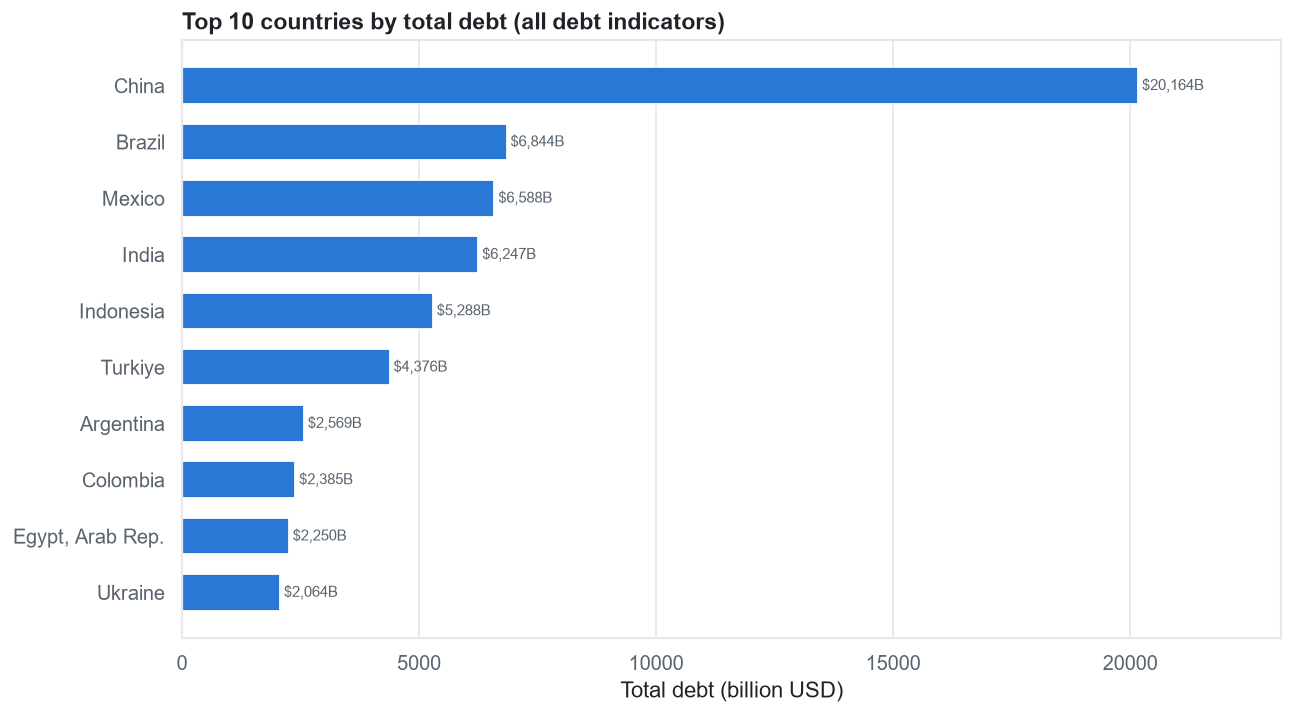

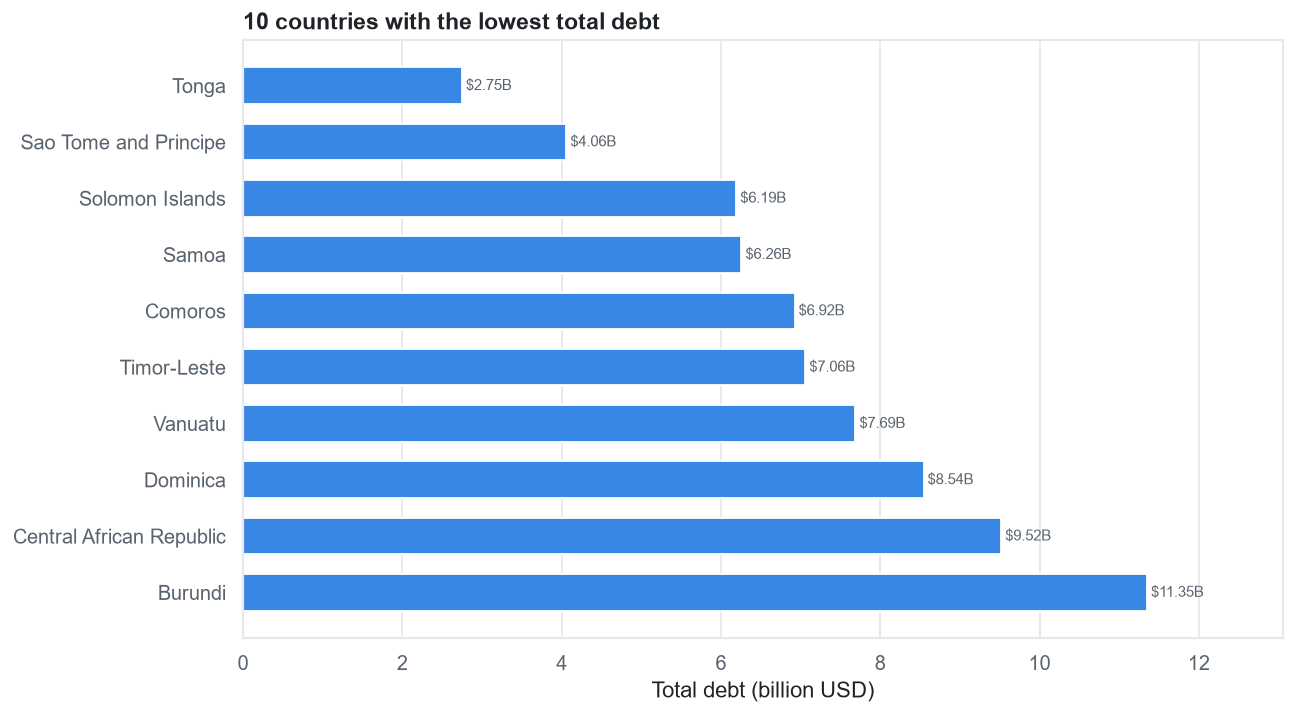

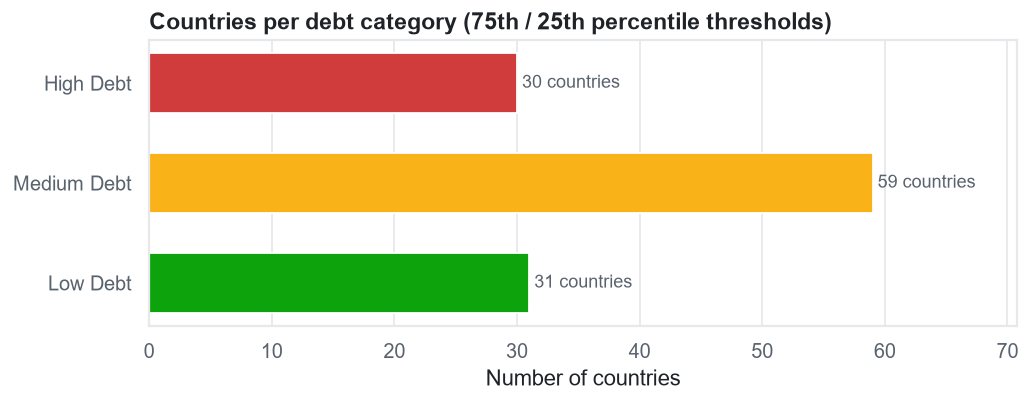

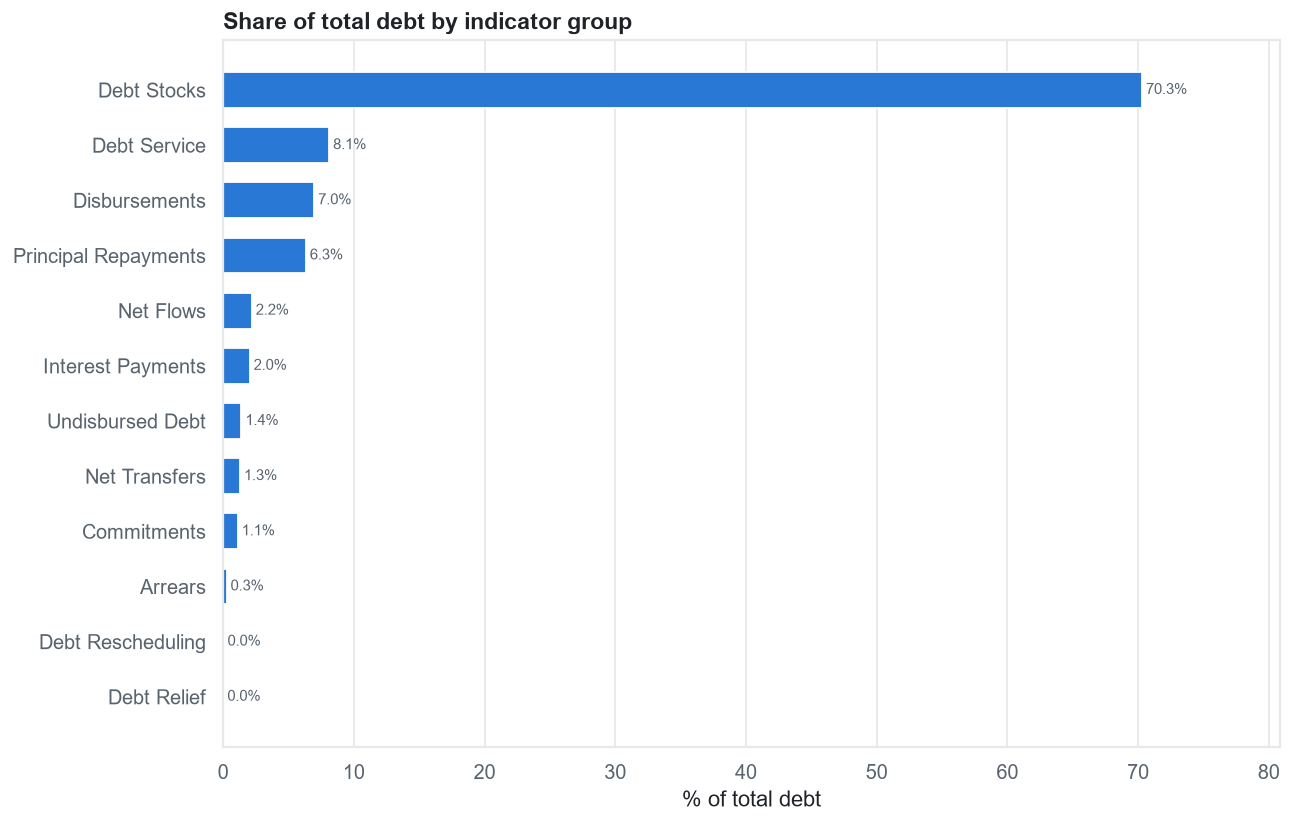

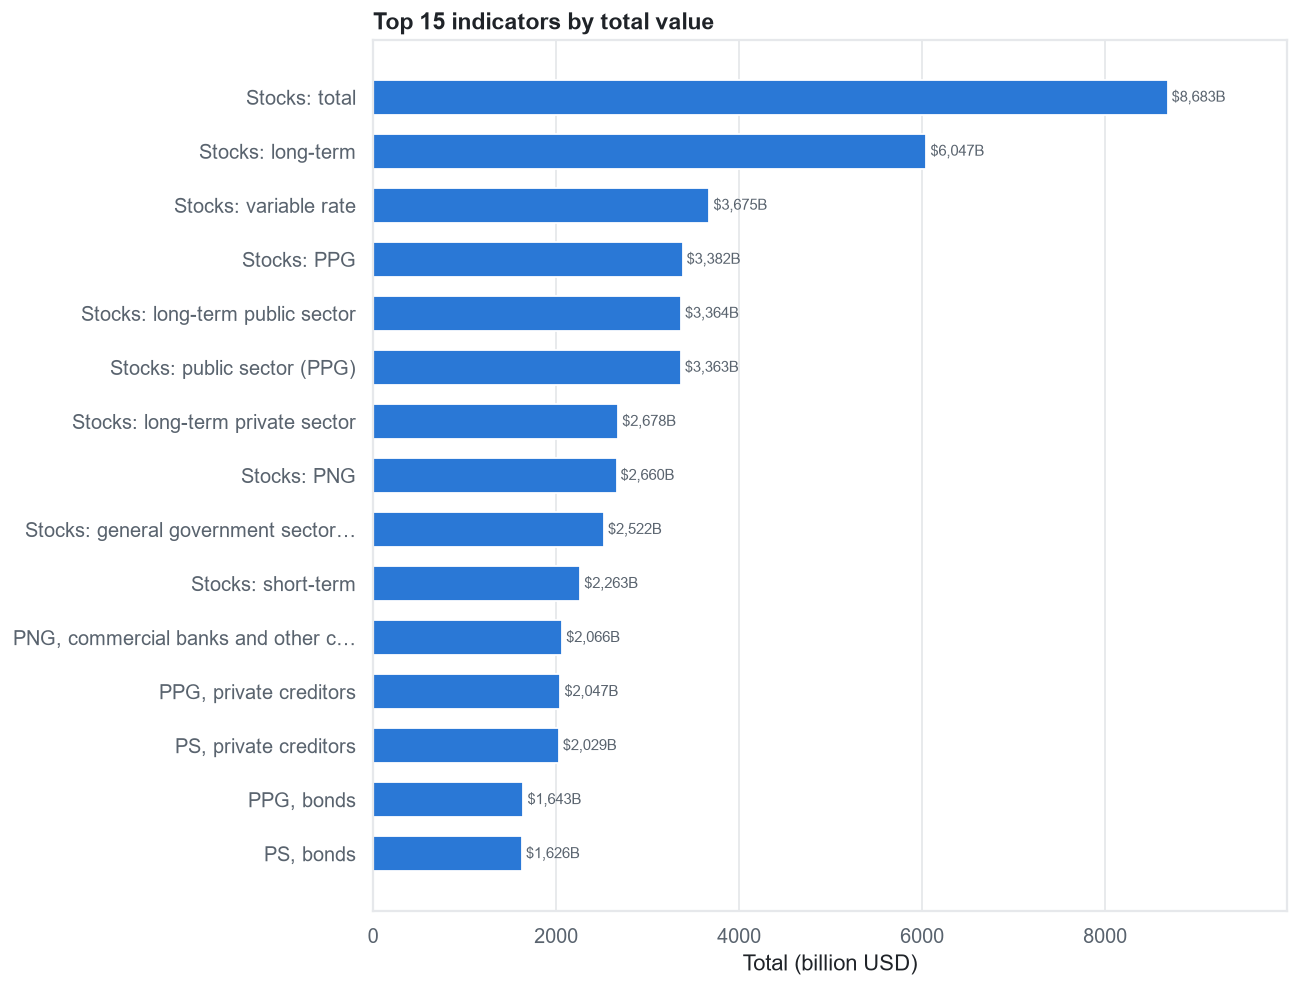

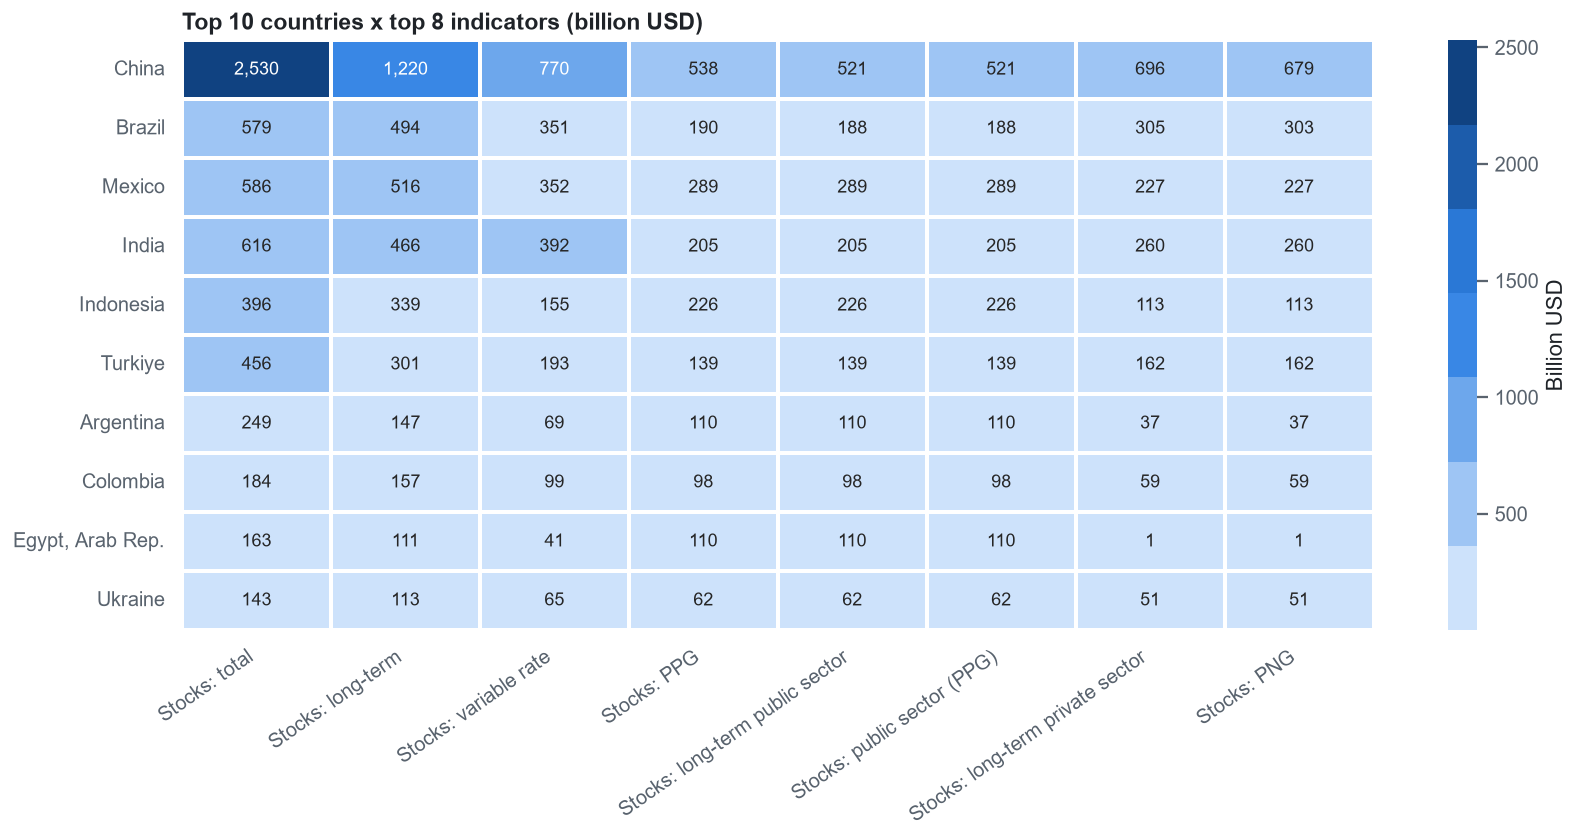

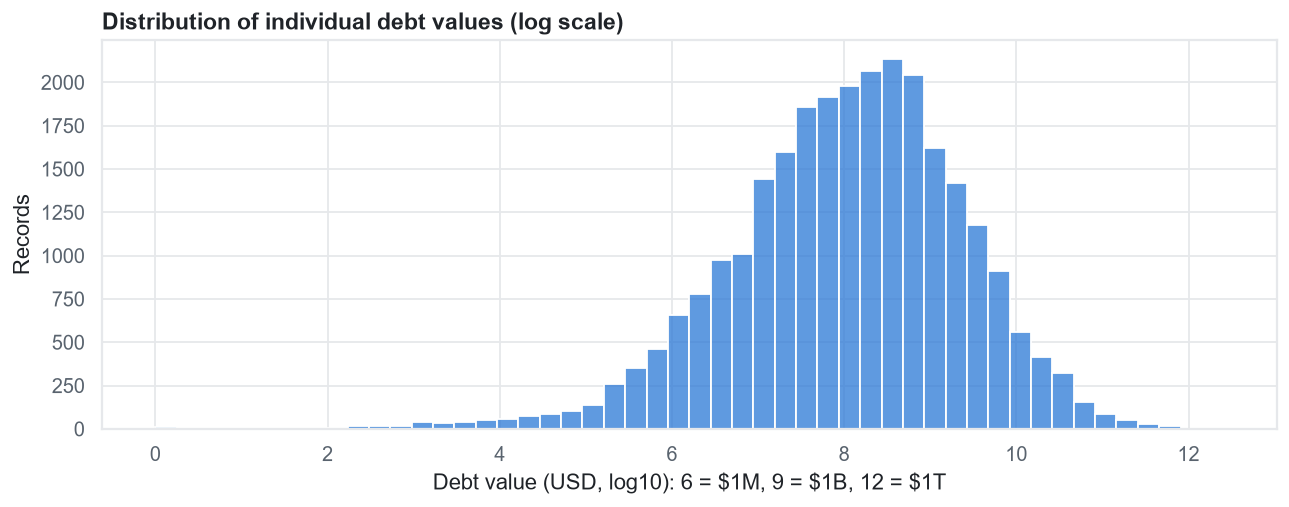

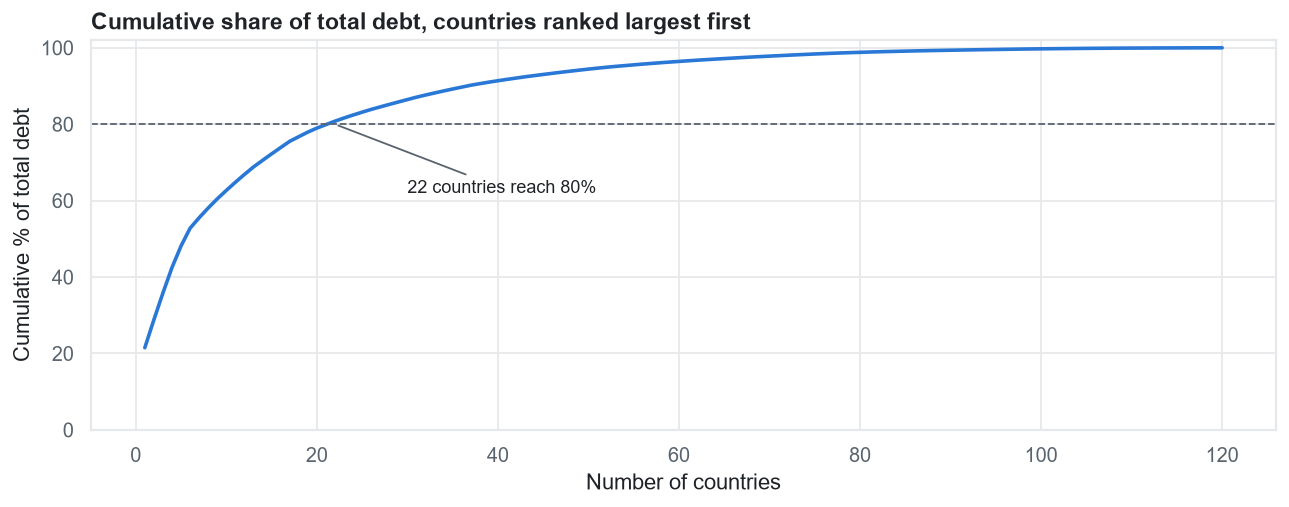

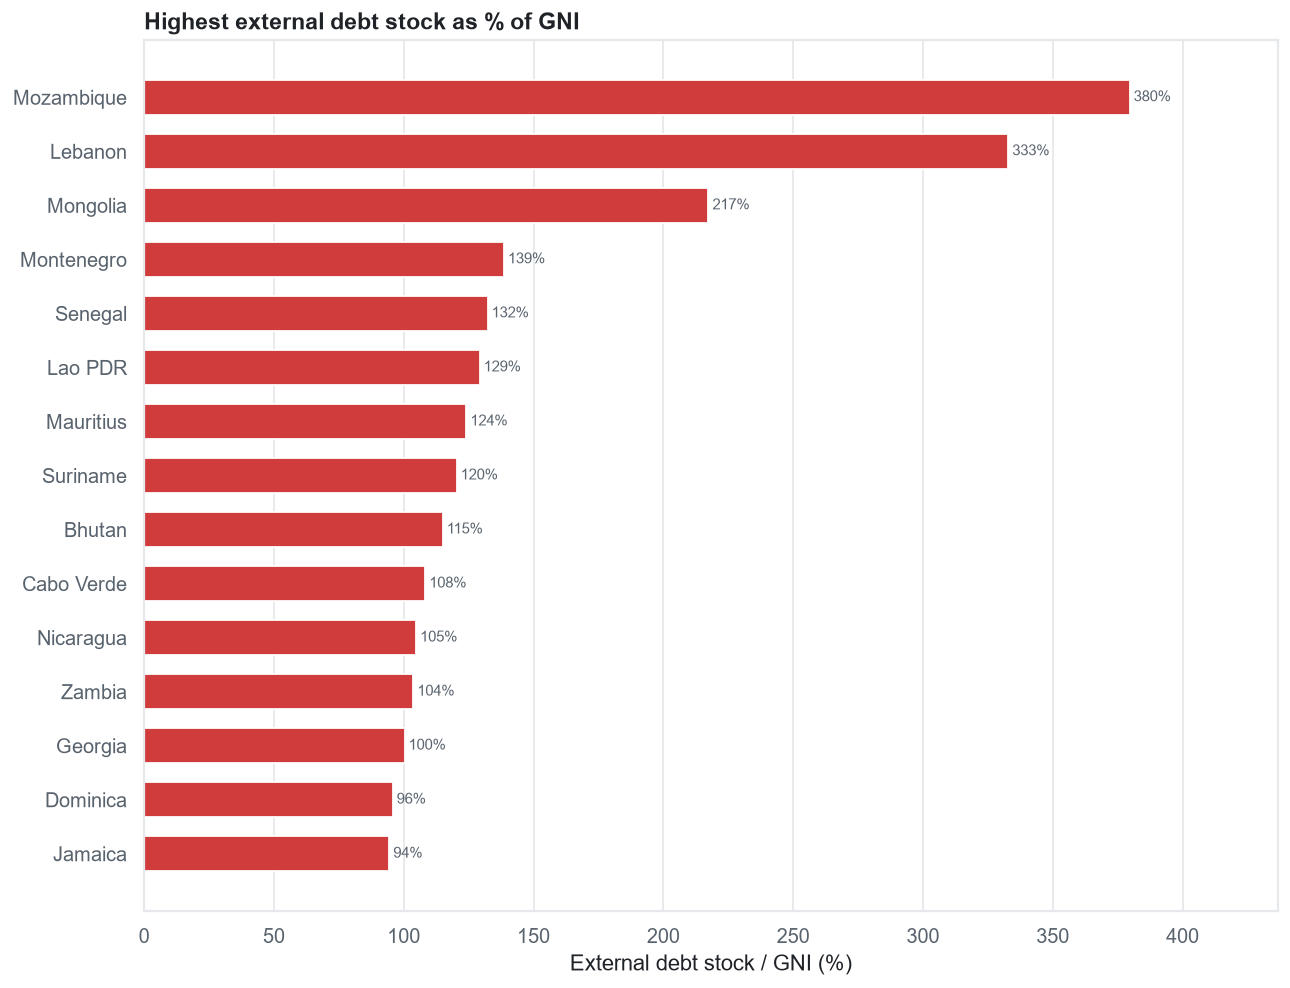

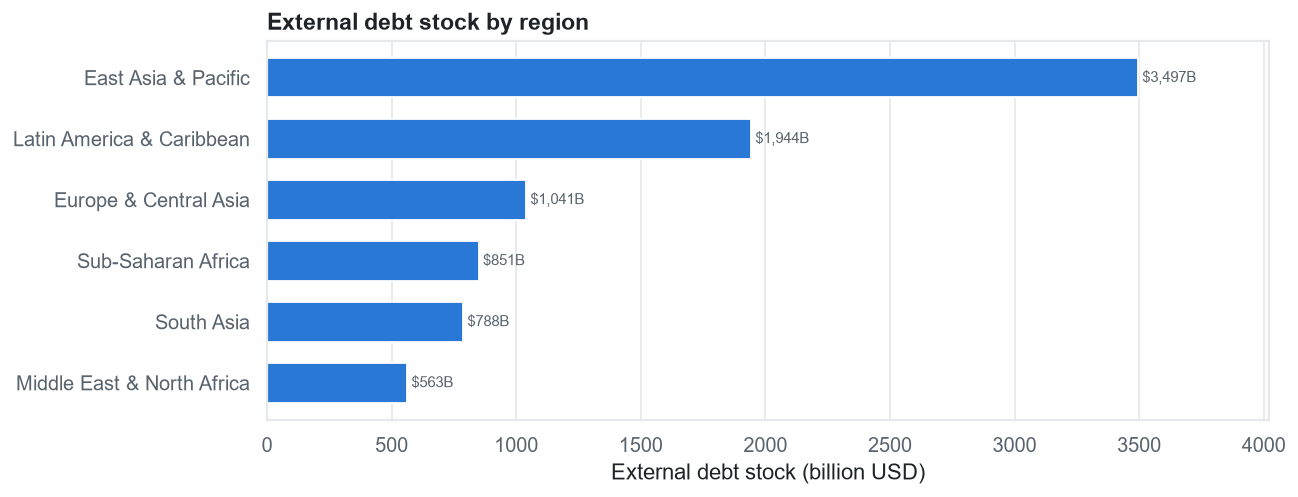

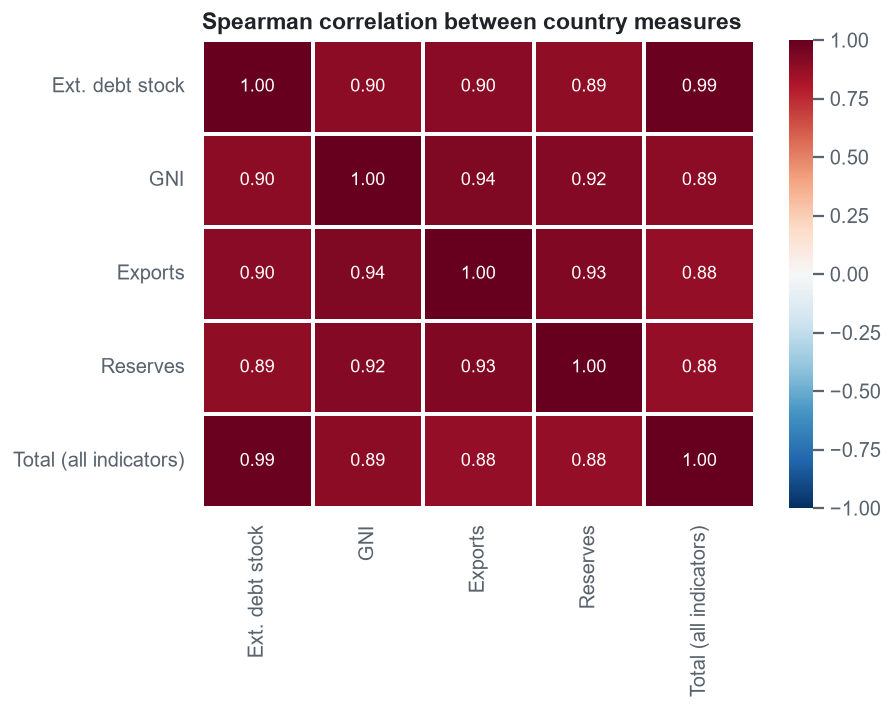

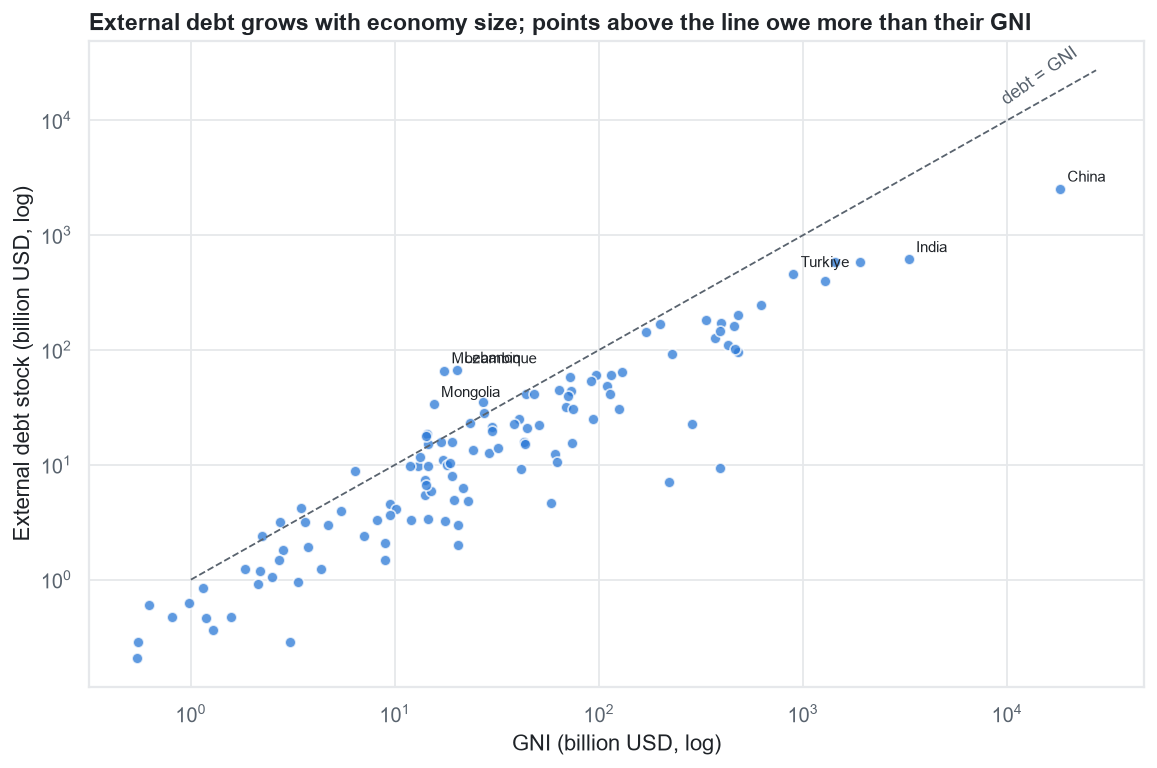

In [27]:
figs = plotting.make_all(df, cs, ind, grp, region, corr)
for f in figs:
    if f.endswith('.png'):
        display(Image(filename=str(config.FIGURES_DIR / f), width=850))

## 6. Insights

In [28]:
f = eda.findings(cs, ind, grp, region, income)
json.loads(json.dumps(f, default=str))

{'countries': 120,
 'indicators': 441,
 'total_debt_trillion': 93.79674257165037,
 'external_debt_stock_trillion': 8.6830965337895,
 'top_country': 'China',
 'top_country_pct': 21.49743468379738,
 'top5_countries': ['China', 'Brazil', 'Mexico', 'India', 'Indonesia'],
 'top5_pct': 48.11550536508463,
 'countries_for_80pct': 22,
 'lowest_country': 'Tonga',
 'lowest_country_billion': 2.746667038937589,
 'top_indicator': 'External debt stocks, total (DOD, current US$)',
 'top_indicator_pct': 9.257354035676206,
 'top_group': 'Debt Stocks',
 'top_group_pct': 70.29689125652278,
 'category_counts': {'Medium Debt': 59, 'Low Debt': 31, 'High Debt': 30},
 'highest_debt_to_gni': [['Mozambique', 379.6],
  ['Lebanon', 332.9],
  ['Mongolia', 217.4],
  ['Montenegro', 138.6],
  ['Senegal', 132.3]],
 'median_debt_to_gni': 45.220419509497866,
 'countries_debt_over_gni_60': 39,
 'top_region': 'East Asia & Pacific',
 'top_region_billion': 3496.7089776184,
 'highest_ratio_income_group': 'Upper middle income'

**Summary**
- Debt is concentrated: China alone is about a fifth of the total, the top 5 about half, and ~22 of 120 countries make up 80%.
- Debt-stock indicators dominate the summed value; summing all indicators double-counts, so the external debt stock is the better headline figure.
- The largest borrowers are not the most stretched: relative to GNI, Mozambique, Lebanon and Mongolia carry the heaviest load, and low-income countries owe the most relative to their economies.

See `reports/EDA_Report.md` and `reports/Insights_Report.md` for the full write-up.